# 03 — Corrected frozen evaluation and graphics

Every model is reloaded from `results/arsenal_isolated/models/`; all scores are recomputed on the corrected Arsenal validation/test fixtures. No model fitting occurs here.

In [1]:
from pathlib import Path
import sys, json, os
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'experiments/isolated_arsenal.py').exists())
sys.path.insert(0,str(ROOT))
os.environ.setdefault('MPLCONFIGDIR',str(ROOT/'work/matplotlib'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, joblib
from IPython.display import display, Markdown, Image
from experiments import train
from experiments.isolated_arsenal import OUTPUT
RUN=OUTPUT
REVIEW=ROOT/'results/arsenal_isolated_review'
(REVIEW/'figures').mkdir(parents=True,exist_ok=True)
record=json.loads((RUN/'manifest.json').read_text())
for rel,digest in record['artifact_sha256'].items():
    assert train.digest(RUN/rel)==digest,rel
features=record['features']
plt.rcParams.update({'figure.figsize':(11,5),'axes.spines.top':False,'axes.spines.right':False})
def finish(name):
    plt.tight_layout(); plt.savefig(REVIEW/'figures'/f'{name}.png',dpi=110,bbox_inches='tight'); plt.show(); plt.close()
def load(population,split):
    folder=RUN/population/split
    return (pd.read_csv(folder/'X.csv').astype(np.float32),pd.read_csv(folder/'y.csv').target_result.map({'A':0,'D':1,'H':2}).to_numpy(),pd.read_csv(folder/'index.csv'))
def predict(name,x):
    if name.endswith('mlp'):
        return train.predict_checkpoint(RUN/'models'/f'{name}_best.pt',x).to_numpy()
    return joblib.load(RUN/'models'/f'{name}.joblib').predict_proba(x)
metrics=pd.read_csv(RUN/'evaluation/metrics.csv')
names=metrics.model.drop_duplicates().tolist()
# Source duplicate is a deterministic replication, excluded from model selection.
candidates=[n for n in names if n!='league_frozen_source_mlp']
validation=metrics.query("split=='validation'").set_index('model').loc[candidates]
selected=validation.log_loss.idxmin()


/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


,model,split,population,log_loss,brier_multiclass,accuracy,n
0,arsenal_mlp,validation,Arsenal,0.864435,0.503668,0.702703,74
1,league_mlp,validation,Arsenal,0.797180,0.453334,0.675676,74
2,full_finetune_mlp,validation,Arsenal,0.796803,0.453112,0.689189,74
3,league_frozen_source_mlp,validation,Arsenal,0.797180,0.453334,0.675676,74
4,head_finetune_mlp,validation,Arsenal,0.797128,0.453307,0.675676,74
5,league_random_forest,validation,Arsenal,0.828401,0.471868,0.702703,74
6,league_dummy,validation,Arsenal,1.040882,0.628818,0.472973,74
7,arsenal_mlp,test,Arsenal,0.959723,0.569044,0.600000,75
8,league_mlp,test,Arsenal,0.908240,0.533728,0.613333,75
9,full_finetune_mlp,test,Arsenal,0.908132,0.533687,0.600000,75


Validation-selected candidate for diagnostics: full_finetune_mlp
Selection is retrospective within this fixed candidate set; test does not choose it.


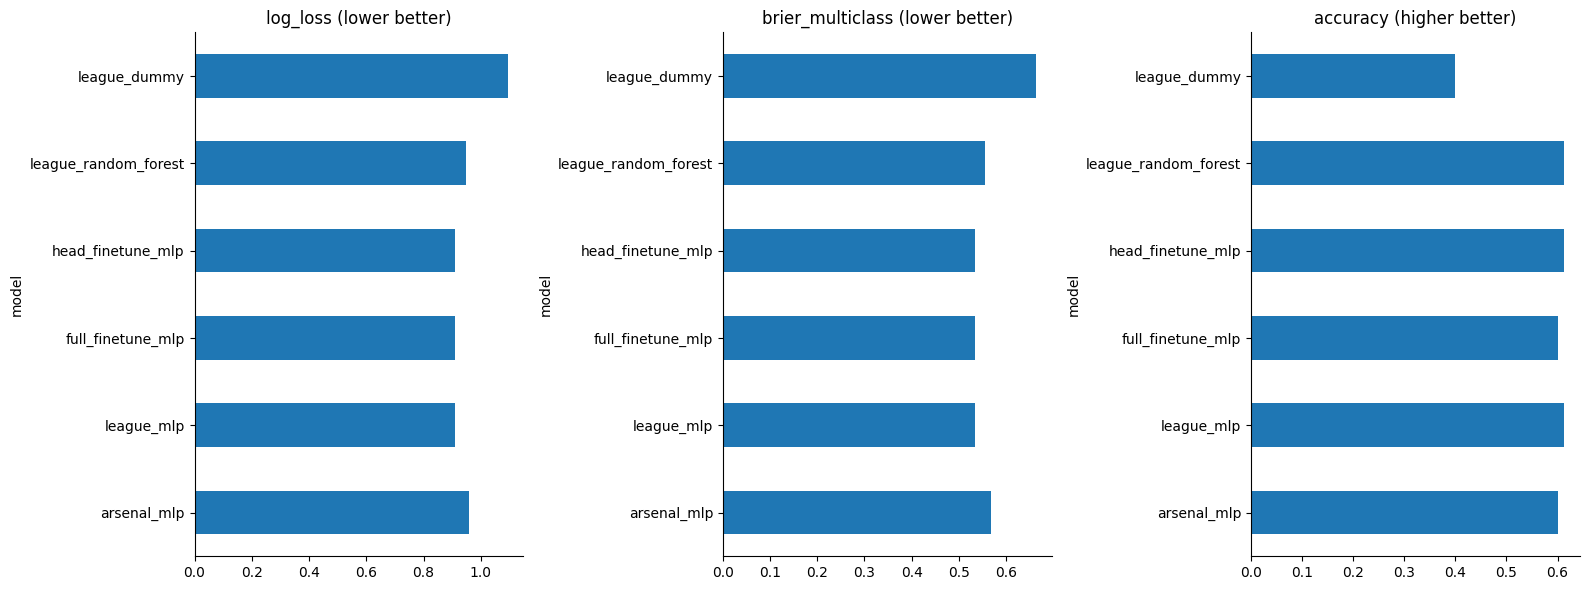

In [2]:
for split in ['validation','test']:
    x,y,meta=load('arsenal',split)
    for name in names:
        p=predict(name,x); saved=pd.read_csv(RUN/'evaluation'/f'{name}_{split}_predictions.csv')
        assert saved.match_id.tolist()==meta.match_id.tolist()
        np.testing.assert_allclose(saved[['p_A','p_D','p_H']].to_numpy().astype(p.dtype),p,rtol=0,atol=1e-15)
        row=metrics.query('model==@name and split==@split').iloc[0]
        for metric,value in train.score(y,p).items(): np.testing.assert_allclose(value,row[metric],rtol=0,atol=1e-12)
display(metrics)
print('Validation-selected candidate for diagnostics:',selected)
print('Selection is retrospective within this fixed candidate set; test does not choose it.')
fig,axs=plt.subplots(1,3,figsize=(16,6));test=metrics.query("split=='test'").set_index('model').loc[candidates]
for ax,m in zip(axs,['log_loss','brier_multiclass','accuracy']): test[m].plot.barh(ax=ax);ax.set_title(m+(' (higher better)' if m=='accuracy' else ' (lower better)'))
finish('12_test_metrics')

## Paired uncertainty
League-minus-Arsenal-only MLP test log loss, paired by fixture and resampled by month (1,000 bootstrap replicates, seed 42). This measures test-sample variability, not training-seed variability. Negative favors league pretraining. The test period was previously inspected.

contrast             league minus Arsenal-only test log loss
difference                                         -0.051483
interval_95    [-0.09552935343235731, -0.005096979276277151]
replicates                                              1000
dtype: object

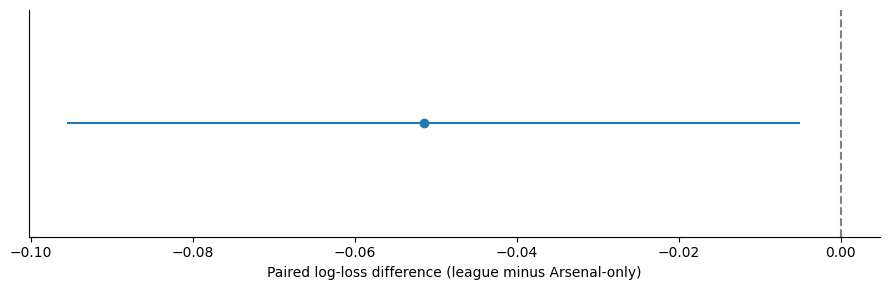

In [3]:
x,y,meta=load('arsenal','test')
a=predict('arsenal_mlp',x);b=predict('league_mlp',x)
delta=-np.log(np.clip(b[np.arange(len(y)),y],1e-15,1))+np.log(np.clip(a[np.arange(len(y)),y],1e-15,1))
months=meta.date.str[:7].to_numpy();groups=np.unique(months);rng=np.random.default_rng(42)
boot=[np.concatenate([delta[months==m] for m in rng.choice(groups,size=len(groups),replace=True)]).mean() for _ in range(1000)]
lo,hi=np.quantile(boot,[.025,.975]);point=delta.mean()
comparison={'contrast':'league minus Arsenal-only test log loss','difference':float(point),'interval_95':[float(lo),float(hi)],'replicates':1000}
(REVIEW/'comparison.json').write_text(json.dumps(comparison,indent=2))
display(pd.Series(comparison))
fig,ax=plt.subplots(figsize=(9,3));ax.hlines(0,lo,hi);ax.plot(point,0,'o');ax.axvline(0,color='grey',ls='--');ax.set_xlabel('Paired log-loss difference (league minus Arsenal-only)');ax.set_yticks([]);finish('13_paired_uncertainty')

## Calibration and confusion
Five fixed bins show Arsenal win probability versus observed wins for the validation-selected candidate and dummy. Empty bins are omitted; bin counts are exported. Confusion uses A/D/H match outcomes.

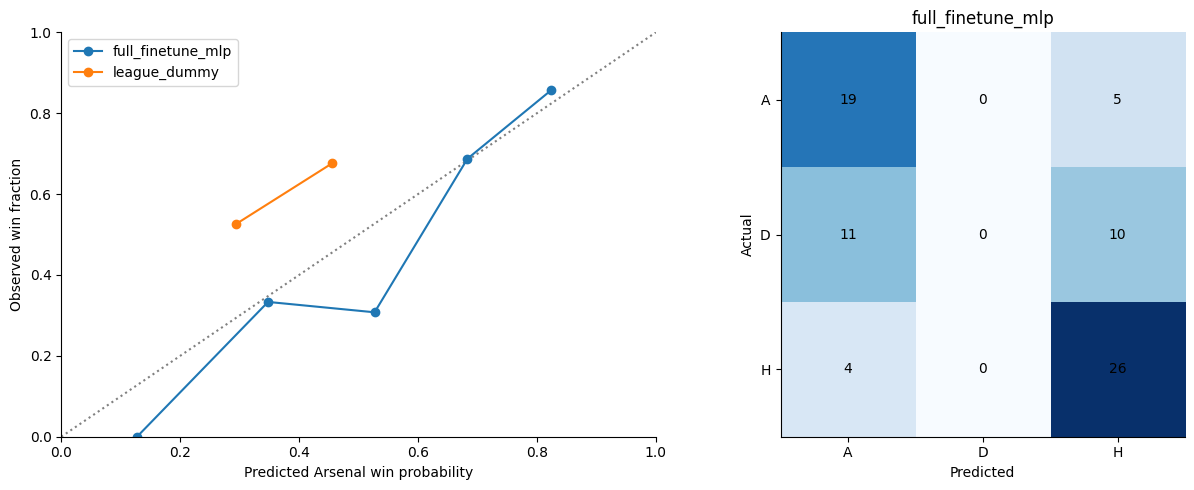

,bin,mean_prediction,observed_rate,n,model
0,0,0.127415,0.000000,1,full_finetune_mlp
1,1,0.347745,0.333333,6,full_finetune_mlp
2,2,0.526924,0.307692,13,full_finetune_mlp
3,3,0.683164,0.687500,48,full_finetune_mlp
4,4,0.824073,0.857143,7,full_finetune_mlp
0,1,0.294315,0.526316,38,league_dummy
1,2,0.455055,0.675676,37,league_dummy


In [4]:
from sklearn.metrics import confusion_matrix
fig,axs=plt.subplots(1,2,figsize=(13,5));axs[0].plot([0,1],[0,1],':',color='grey');cal=[]
home=meta.home_team.eq('Arsenal').to_numpy();won=np.where(home,y==2,y==0)
for name in [selected,'league_dummy']:
    p=predict(name,x);win=np.where(home,p[:,2],p[:,0]);bin_id=np.minimum((win*5).astype(int),4)
    table=pd.DataFrame({'bin':bin_id,'probability':win,'won':won}).groupby('bin').agg(mean_prediction=('probability','mean'),observed_rate=('won','mean'),n=('won','size')).reset_index();table['model']=name;cal.append(table)
    axs[0].plot(table.mean_prediction,table.observed_rate,'o-',label=name)
axs[0].set(xlabel='Predicted Arsenal win probability',ylabel='Observed win fraction',xlim=(0,1),ylim=(0,1));axs[0].legend()
p=predict(selected,x);cm=confusion_matrix(y,p.argmax(1),labels=[0,1,2]);axs[1].imshow(cm,cmap='Blues')
for i in range(3):
    for j in range(3): axs[1].text(j,i,str(cm[i,j]),ha='center',va='center')
axs[1].set(xticks=range(3),yticks=range(3),xticklabels=['A','D','H'],yticklabels=['A','D','H'],xlabel='Predicted',ylabel='Actual',title=selected)
finish('14_calibration_confusion');cal=pd.concat(cal);cal.to_csv(REVIEW/'calibration_bins.csv',index=False);display(cal)

## Interpretation
These corrected arms use isolated source data. Full and head-only fine-tuning make tiny changes in this run. Accuracy and probability scores can rank models differently. No other target teams were trained. Non-Arsenal target-transfer results from the old study are not reused: that is a different evaluation population and not needed for the requested Arsenal experiments.